In [17]:
import math
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from pygam import LogisticGAM, s

import pickle

In [2]:
train = pd.read_csv('../Data/train_features_imputed.csv')
oot1 = pd.read_csv('../Data/oot1_features_imputed.csv')
oot2 = pd.read_csv('../Data/oot2_features_imputed.csv')

all_features = pickle.load(open('../Files/all_features.pkl', 'rb'))
identifier_cols = all_features['identifier_features']
features_to_select = pickle.load(open('../Files/selected_features_before_vif.csv', 'rb'))['final_selected_features_before_vif']

In [3]:
identifier_cols

['id', 'stmt_date', 'data_type', 'default', 'ateco_sector']

In [4]:
vif = pd.read_csv('../Files/VIF.csv').sort_values(by='VIF', ascending=False)
features_to_select = vif.query('feature != "const"')['feature'].tolist()
vif_feats = list(vif.query('VIF <= 5')['feature'])
vif_feats

['st_debt_share',
 'equity_to_assets',
 'operating_loss_flag',
 'nonpositive_ebitda_flag',
 'receivables_to_assets',
 'account_payables_to_assets',
 'net_loss_flag',
 'operating_cashflow_to_liabilities',
 'cash_to_debt_st',
 'current_assets_to_debt_st',
 'net_profit_to_assets',
 'operating_cashflow_to_assets',
 'cash_flow_to_debt',
 'cash_to_assets',
 'negative_equity_flag',
 'ebitda_to_assets',
 'interest_coverage_proxy',
 'operating_margin',
 'debt_to_ebitda',
 'const']

In [5]:
final_model_feats = [c for c in features_to_select if c in vif_feats]
len(final_model_feats), len(features_to_select), len(vif_feats)

(19, 22, 20)

In [28]:
final_logit_feats = ['net_loss_flag',
 'account_payables_to_assets',
 'st_debt_share',
 'receivables_to_assets',
 'nonpositive_ebitda_flag',
 'operating_loss_flag',
 'negative_equity_flag',
 'cash_to_assets',
 'equity_to_assets',
 'net_profit_to_assets']
len(final_logit_feats)

10

In [29]:
train = train[identifier_cols + final_logit_feats]
oot1 = oot1[identifier_cols + final_logit_feats]
oot2 = oot2[identifier_cols + final_logit_feats]

In [30]:
X_train_gam = train[final_logit_feats].astype(float)
y_train_gam = train["default"].astype(int)

In [31]:
terms = s(0, n_splines=8)
for i in range(1, len(final_logit_feats)):
    terms += s(i, n_splines=8)

gam = LogisticGAM(terms, max_iter=500).fit(X_train_gam, y_train_gam)
gam.summary()

LogisticGAM                                                                                               
=============================================== ==========================================================
Distribution:                      BinomialDist Effective DoF:                                      17.034
Link Function:                        LogitLink Log Likelihood:                                -30340.4122
Number of Samples:                       475389 AIC:                                            60714.8924
                                                AICc:                                           60714.8938
                                                UBRE:                                               2.1277
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                    0.133
Feature Function                  Lam

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_56886/732514998.py:6: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


In [32]:
gam_pvalues = pd.DataFrame({
    "feature": final_logit_feats,
    "p_value": gam.statistics_["p_values"][:len(final_logit_feats)],
})
display(gam_pvalues)

,feature,p_value
0,net_loss_flag,0.000000
1,account_payables_to_assets,0.000000
2,st_debt_share,0.000000
3,receivables_to_assets,0.000000
4,nonpositive_ebitda_flag,0.000000
5,operating_loss_flag,0.002909
6,negative_equity_flag,0.000000
7,cash_to_assets,0.000000
8,equity_to_assets,0.000000
9,net_profit_to_assets,0.000000


In [34]:
for name, data in [("Train", train), ("OOT1", oot1), ("OOT2", oot2)]:
    X = data[final_logit_feats].astype(float)
    probabilities = gam.predict_proba(X)
    auc = roc_auc_score(data["default"], probabilities)
    print(f"{name} AUC: {auc:.4f}")

Train AUC: 0.7742
OOT1 AUC: 0.7664
OOT2 AUC: 0.7903


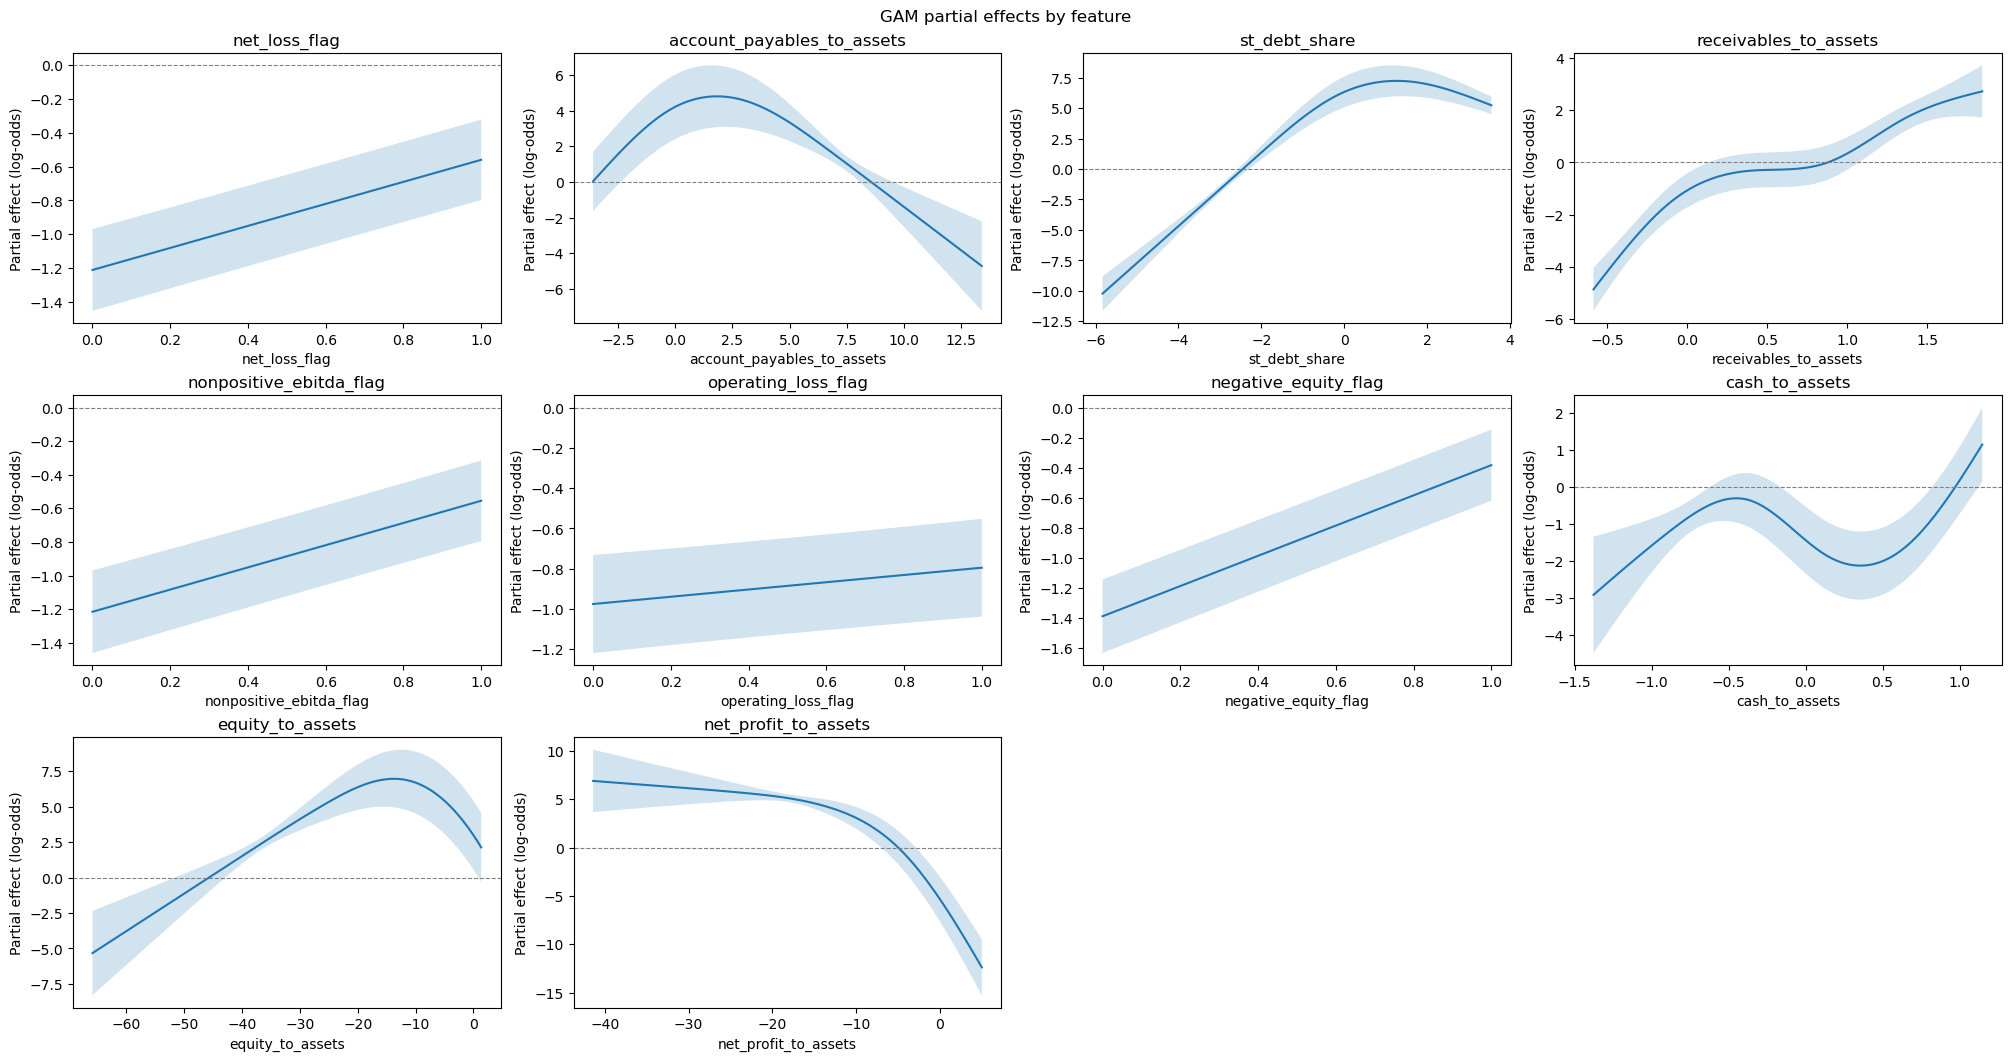

In [35]:
ncols = 4
nrows = math.ceil(len(final_logit_feats) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 3.5 * nrows),
    squeeze=False,
    constrained_layout=True,
)
axes = axes.ravel()

for i, feature in enumerate(final_logit_feats):
    grid = gam.generate_X_grid(term=i)
    effect, interval = gam.partial_dependence(
        term=i, X=grid, width=0.95
    )

    axes[i].plot(grid[:, i], effect)
    axes[i].fill_between(
        grid[:, i], interval[:, 0], interval[:, 1], alpha=0.2
    )
    axes[i].axhline(0, color="gray", linestyle="--", linewidth=0.8)
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Partial effect (log-odds)")

for ax in axes[len(final_logit_feats):]:
    ax.remove()

fig.suptitle("GAM partial effects by feature")
plt.show()